# U-Net: ordinary Riesz MMD versus softmax Riesz

Matched seed-0 MNIST experiments: identical generator initialization, data selections,
latent sampling streams, architecture, Adam settings, and 100 full training epochs.
The ordinary method uses the exact gradient of half the biased empirical Riesz MMD
squared. The softmax method uses the existing multitemperature normalized field and
detached-target regression recipe. Thus this compares complete training rules;
it does not isolate softmax weighting from normalization or gradient scaling.
Both curves report ordinary Riesz MMD squared on the same fixed evaluation subsets.
Image grids use the same fixed evaluation latent identities. This is a single-seed
comparison; no confidence interval or general superiority claim is implied.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import tempfile
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 16, "axes.labelsize": 18, "lines.linewidth": 2,
    "legend.fontsize": 12, "legend.frameon": False,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "xtick.direction": "in", "ytick.direction": "in",
    "axes.grid": True, "figure.figsize": (6, 4),
})
# Test the renderer; a latex executable alone does not establish working packages.
plt.rcParams["text.usetex"] = True
try:
    with tempfile.TemporaryDirectory(prefix="riesz_tex_check_") as temp_dir:
        probe, probe_ax = plt.subplots()
        probe_ax.set_ylabel(r"$\mathrm{MMD}^2$")
        probe.savefig(Path(temp_dir) / "probe.pdf")
        plt.close(probe)
except Exception:
    plt.close("all")
    plt.rcParams["text.usetex"] = False
    print("LaTeX rendering unavailable; using Matplotlib mathtext.")

COLORS = {"Standard Riesz": "steelblue", "Softmax Riesz": "darkorange"}


In [2]:
ROOT = Path.cwd()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
RESULTS = ROOT / "results" / "mnist"
FIGURES = ROOT / "figures" / "unet_riesz_comparison_seed0"
RUNS = {
    "Standard Riesz": RESULTS / "mnist_riesz_unet32_noise784_resampled_fulltrain_particles64_batch256_epochs100_lr0.001_seed0_gpu_20261014_170255_2687530",
    "Softmax Riesz": RESULTS / "mnist_softmax-riesz_unet32_noise784_resampled_fulltrain_particles64_batch256_epochs100_lr0.001_seed0_gpu_20261014_165242_2685776",
}
FIGURES.mkdir(parents=True, exist_ok=True)


In [3]:
configs, trajectories = {}, {}
for name, run in RUNS.items():
    configs[name] = json.loads((run / "config.json").read_text())
    with (run / "metrics.csv").open() as stream:
        rows = list(csv.DictReader(stream))
    trajectories[name] = {
        key: np.array([float(row[key]) for row in rows])
        for key in ("epoch", "update", "train_subset_mmd_squared", "heldout_mmd_squared", "elapsed_seconds")
    }
    values = trajectories[name]
    assert len(rows) == 101 and np.array_equal(values["epoch"], np.arange(101)), name
    assert values["update"][-1] == configs[name]["total_updates"] == 23500, name
    assert np.all(np.isfinite(values["heldout_mmd_squared"])), name
    assert np.all(values["train_subset_mmd_squared"] > 0), name
    assert np.all(values["heldout_mmd_squared"] > 0), name

standard, softmax = configs.values()
assert standard["objective"] == "riesz" and softmax["objective"] == "softmax-riesz"
matched_keys = ["architecture", "parameter_count", "seed", "particles", "latent_dim",
                "training_latent_sampling", "training_latent_seed", "evaluation_latent_sampling",
                "actual_target_size", "actual_eval_size", "target_batch_size", "eval_size",
                "epochs", "learning_rate", "optimizer", "adam_betas", "adam_eps", "weight_decay",
                "iteration_unit", "snapshot_iterations", "updates_per_iteration", "total_updates"]
for key in matched_keys:
    assert standard[key] == softmax[key], key

def checksum(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

for filename in ["data_indices.json", "particles_epoch_000000.png"]:
    assert len({checksum(run / filename) for run in RUNS.values()}) == 1, filename

summary = {
    "comparison": "single_seed_complete_training_recipes",
    "seed": 0, "epochs": 100, "updates": 23500,
    "matched_keys": matched_keys,
    "identical_initial_image_grid": True, "identical_data_indices": True,
    "late_epoch_window": [91, 100], "runs": {},
}
for name, run in RUNS.items():
    values = trajectories[name]
    summary["runs"][name] = {
        "path": str(run.relative_to(ROOT)),
        "config_sha256": checksum(run / "config.json"),
        "metrics_sha256": checksum(run / "metrics.csv"),
        "final_train_mmd_squared": float(values["train_subset_mmd_squared"][-1]),
        "final_heldout_mmd_squared": float(values["heldout_mmd_squared"][-1]),
        "mean_heldout_mmd_squared_epochs_91_100": float(values["heldout_mmd_squared"][-10:].mean()),
        "elapsed_seconds": float(values["elapsed_seconds"][-1]),
    }
base = summary["runs"]["Standard Riesz"]
soft = summary["runs"]["Softmax Riesz"]
for key in ["final_heldout_mmd_squared", "mean_heldout_mmd_squared_epochs_91_100"]:
    summary["softmax_relative_reduction_" + key] = 1 - soft[key] / base[key]
(FIGURES / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(json.dumps(summary, indent=2))


{
  "comparison": "single_seed_complete_training_recipes",
  "seed": 0,
  "epochs": 100,
  "updates": 23500,
  "matched_keys": [
    "architecture",
    "parameter_count",
    "seed",
    "particles",
    "latent_dim",
    "training_latent_sampling",
    "training_latent_seed",
    "evaluation_latent_sampling",
    "actual_target_size",
    "actual_eval_size",
    "target_batch_size",
    "eval_size",
    "epochs",
    "learning_rate",
    "optimizer",
    "adam_betas",
    "adam_eps",
    "weight_decay",
    "iteration_unit",
    "snapshot_iterations",
    "updates_per_iteration",
    "total_updates"
  ],
  "identical_initial_image_grid": true,
  "identical_data_indices": true,
  "late_epoch_window": [
    91,
    100
  ],
  "runs": {
    "Standard Riesz": {
      "path": "results/mnist/mnist_riesz_unet32_noise784_resampled_fulltrain_particles64_batch256_epochs100_lr0.001_seed0_gpu_20261014_170255_2687530",
      "config_sha256": "15a70ebb36bb48ff286ce8a05894d0ac0e1db564907ad54d04a4b8

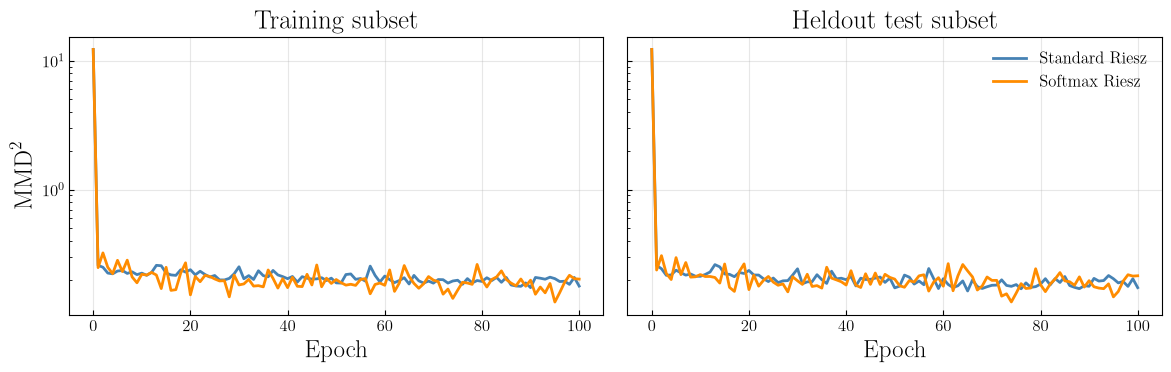

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric, title in zip(axes, ["train_subset_mmd_squared", "heldout_mmd_squared"],
                              ["Training subset", "Heldout test subset"]):
    for name, values in trajectories.items():
        ax.plot(values["epoch"], values[metric], color=COLORS[name], label=name)
    ax.set_xlabel("Epoch")
    ax.set_title(title)
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(r"$\mathrm{MMD}^2$")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "unet_riesz_mmd_comparison.pdf", bbox_inches="tight")
fig.savefig(FIGURES / "unet_riesz_mmd_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


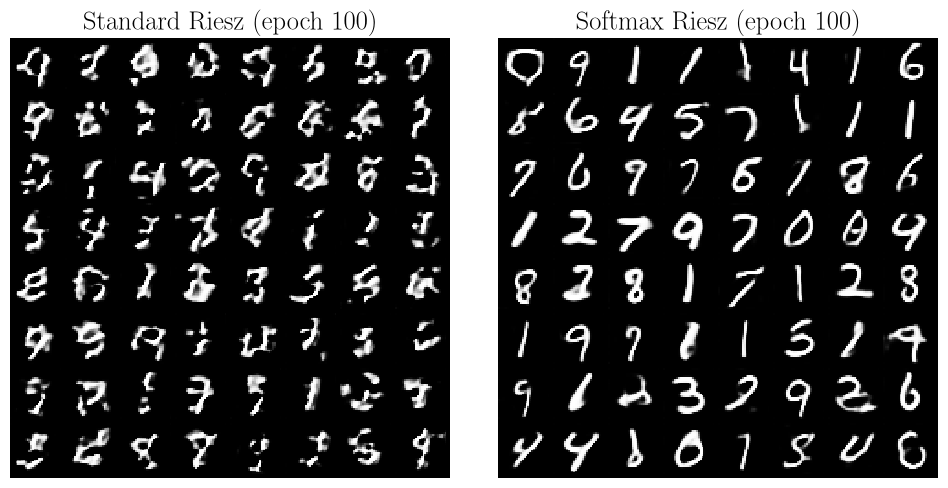

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, run) in zip(axes, RUNS.items()):
    pixels = np.asarray(Image.open(run / "particles_epoch_000100.png"))
    assert pixels.shape == (960, 960), (name, pixels.shape)
    ax.imshow(pixels, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(name + " (epoch 100)")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "unet_riesz_final_digits.pdf", bbox_inches="tight")
fig.savefig(FIGURES / "unet_riesz_final_digits.png", dpi=200, bbox_inches="tight")
plt.show()


The epoch-100 grids show a substantial visual difference: ordinary Riesz produces
many fragmented and ambiguous shapes, while softmax Riesz produces more continuous,
recognizable strokes. This is a visual assessment of the displayed fixed latent set.

Final heldout MMD squared is 0.17350 for ordinary Riesz and 0.21450 for softmax
Riesz. Averaged across epochs 91--100 it is 0.19525 and 0.18544, respectively:
a 5.0% reduction for softmax. Thus the visual improvement is much stronger than
the difference in this pixel-space distribution metric, and the final-epoch metric
alone favors ordinary Riesz. No classifier-based quality or coverage score was
computed. These results support the complete softmax training recipe for this
seed, without isolating its weighting, normalization, or regression scaling.